# 02 · How good is the neural surrogate?

Step 3b trained two neural networks to replace the FEM solver for damaged cantilever beams:

- **Plain**: the network sees all 7 inputs and predicts everything itself.
- **Hybrid**: the exact formula gives the healthy frequencies, and the network only learns how much the damage
  lowers them (as a ratio), using just the 2 damage inputs.

This notebook tests both **on the 600 beams they never saw during training** (the test set) and answers:

1. Can each surrogate see the damage, or is the damage hidden inside its error?
2. How small a crack can it still resolve?
3. How did training go?
4. How much faster than the FEM is it?

**Before running:** generate the data and train the models (Steps 3a and 3b):

```
python -m beamtwin.surrogate.data_generation --n-samples 4000
python -m beamtwin.surrogate.train
```

In [1]:
%load_ext autoreload
%autoreload 2

import json
import time

import matplotlib.pyplot as plt
import numpy as np

from beamtwin.plotting import INK_2, MARKERS, MUTED, SERIES, SURFACE, apply_style, figures_dir, project_root
from beamtwin.surrogate.data_generation import simulate_one
from beamtwin.surrogate.evaluation import evaluate, format_report, split_indices
from beamtwin.surrogate.features import healthy_frequencies
from beamtwin.surrogate.model import Surrogate

apply_style()
ROOT, FIGURES = project_root(), figures_dir()

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Same data and the same split as training, so the test beams really are unseen.
data = np.load(ROOT / "data" / "processed" / "beam_dataset.npz")
X, Y = data["X"], data["Y"]
_, _, test = split_indices(len(X), seed=0)
X_test, Y_test = X[test], Y[test]

models = {kind: Surrogate.load(ROOT / "models" / f"surrogate_{kind}.pt") for kind in ("plain", "hybrid")}
predictions = {kind: model.predict(X_test) for kind, model in models.items()}

COLOR = {"hybrid": SERIES[0], "plain": SERIES[1]}      # fixed colour per model in every figure
MARK = {"hybrid": MARKERS[0], "plain": MARKERS[1]}

for kind in ("plain", "hybrid"):
    print(format_report(f"{kind.upper()} surrogate, test set ({len(X_test)} beams)",
                        evaluate(X_test, Y_test, predictions[kind])))


PLAIN surrogate, test set (600 beams)
                                    Mode 1    Mode 2    Mode 3    Mode 4
Frequency error, mean (%)            0.421     0.385     0.400     0.377
Frequency error, worst (%)           2.797     2.119     2.397     2.218
Damage drop, true mean (%)           1.340     1.500     1.518     1.543
Damage drop error (% points)         0.415     0.379     0.393     0.370
Signal-to-error ratio                  3.2       4.0       3.9       4.2
Mode-shape error (mean abs)        0.00012

HYBRID surrogate, test set (600 beams)
                                    Mode 1    Mode 2    Mode 3    Mode 4
Frequency error, mean (%)            0.007     0.007     0.006     0.008
Frequency error, worst (%)           0.046     0.035     0.043     0.062
Damage drop, true mean (%)           1.340     1.500     1.518     1.543
Damage drop error (% points)         0.006     0.007     0.006     0.008
Signal-to-error ratio                208.4     227.1     238.9     193.1
Mo

## 1. Can the surrogate see the damage?

Damage lowers each frequency by a small percentage: the **damage drop**. A damage detector reads exactly that
signal, so the question is whether each surrogate predicts it correctly.

Each dot below is one test beam. On the dashed line, the surrogate predicted the drop exactly.

Look out for points **below zero** on the vertical axis: a negative drop would mean damage made the beam
*stiffer*, which is physically impossible. A model that predicts this has not learned the physics.

(A predicted-vs-true plot of the frequencies themselves would look perfect for **both** models, because frequencies
span a 60× range and a 0.4 % error is invisible at that scale. Plotting the drop exposes the difference.)

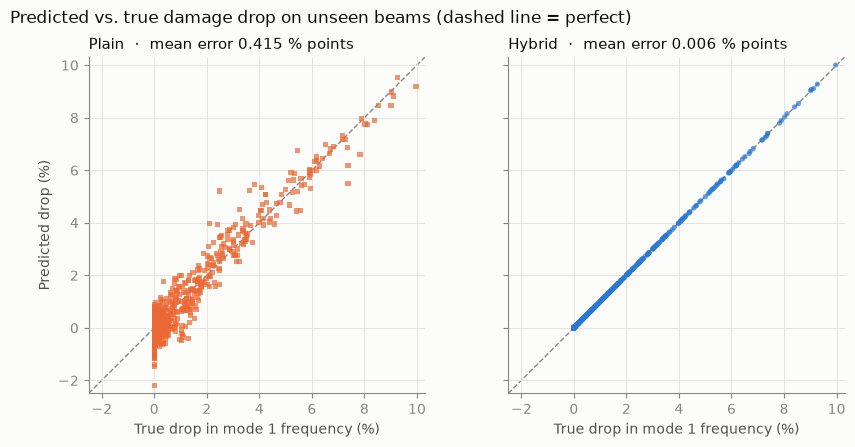

In [3]:
def damage_drop_pct(X, Y):
    # How much damage lowered each frequency, in % of the healthy value. Shape (n, 4).
    return (1 - Y[:, :4] / healthy_frequencies(X)) * 100

true_drop = damage_drop_pct(X_test, Y_test)
pred_drop = {kind: damage_drop_pct(X_test, p) for kind, p in predictions.items()}

MODE = 0                                   # mode 1; change to 1, 2 or 3 to see the others
lim = [min(true_drop[:, MODE].min(), *(p[:, MODE].min() for p in pred_drop.values())) - 0.3,
       max(true_drop[:, MODE].max(), *(p[:, MODE].max() for p in pred_drop.values())) + 0.3]

fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), sharex=True, sharey=True)
for ax, kind in zip(axes, ("plain", "hybrid")):
    ax.plot(lim, lim, color=MUTED, linewidth=1, linestyle="--", zorder=1)
    ax.scatter(true_drop[:, MODE], pred_drop[kind][:, MODE], s=14, color=COLOR[kind],
               marker=MARK[kind], alpha=0.7, edgecolors="none", zorder=2)
    err = np.abs(pred_drop[kind][:, MODE] - true_drop[:, MODE]).mean()
    ax.set_title(f"{kind.capitalize()}  ·  mean error {err:.3f} % points", loc="left")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_xlabel(f"True drop in mode {MODE + 1} frequency (%)")
axes[0].set_ylabel(f"Predicted drop (%)")
fig.suptitle("Predicted vs. true damage drop on unseen beams (dashed line = perfect)",
             x=0.02, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "surrogate_damage_parity.png", dpi=150)
plt.show()

## 2. How small a damage can each surrogate resolve?

Damage is only visible through a surrogate if the drop it causes is clearly bigger than the surrogate's error.
A common rule of thumb is a **signal-to-error ratio of at least 3**.

For each test beam we take the **largest** drop across the four modes (a detector looks at all of them, and damage
near the tip barely affects mode 1 but does affect the higher modes) and compare it with the surrogate's largest
error. Then we ask, for each damage severity: *what share of beams pass the 3× test?*

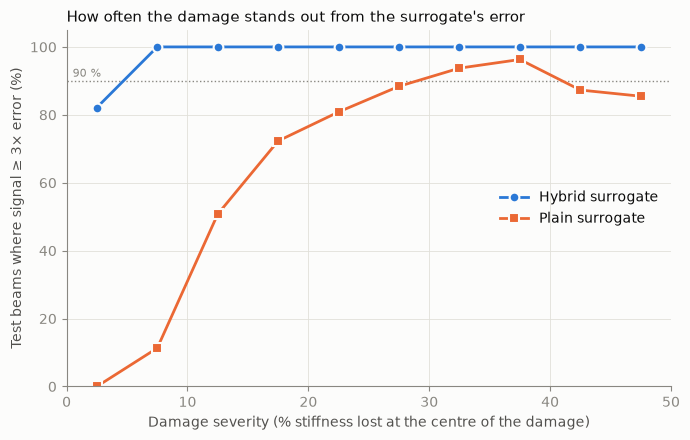

Severity group       Plain    Hybrid
   0-5    %              0%       82%
   5-10   %             11%      100%
  10-15   %             51%      100%
  15-20   %             72%      100%
  20-25   %             81%      100%
  25-30   %             88%      100%
  30-35   %             94%      100%
  35-40   %             96%      100%
  40-45   %             87%      100%
  45-50   %             85%      100%
 plain: at least 90 % of beams resolvable never
hybrid: at least 90 % of beams resolvable from the 5-10 % group upwards


In [4]:
signal = true_drop.max(axis=1)                                              # per beam, largest drop
error = {kind: np.abs(pred_drop[kind] - true_drop).max(axis=1) for kind in predictions}
resolvable = {kind: signal >= 3 * error[kind] for kind in predictions}

severity = X_test[:, 6]
bins = np.linspace(0, 0.5, 11)                                              # groups 5 % of severity wide
centres = (bins[:-1] + bins[1:]) / 2
group = np.digitize(severity, bins[1:-1])
share = {kind: np.array([resolvable[kind][group == g].mean() * 100 for g in range(len(centres))])
         for kind in predictions}

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(90, color=MUTED, linewidth=1, linestyle=":")
ax.annotate("90 %", (0.5, 90), xytext=(0, 3), textcoords="offset points", color=MUTED, fontsize=8)
for kind in ("hybrid", "plain"):
    ax.plot(centres * 100, share[kind], color=COLOR[kind], marker=MARK[kind], markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"{kind.capitalize()} surrogate")
ax.set_xlim(0, 50)
ax.set_ylim(0, 105)
ax.set_xlabel("Damage severity (% stiffness lost at the centre of the damage)")
ax.set_ylabel("Test beams where signal ≥ 3× error (%)")
ax.set_title("How often the damage stands out from the surrogate's error", loc="left")
ax.legend(frameon=False, loc="center right")
fig.tight_layout()
fig.savefig(FIGURES / "surrogate_detection_limit.png", dpi=150)
plt.show()

print(f"{'Severity group':<16}" + "".join(f"{k.capitalize():>10}" for k in ("plain", "hybrid")))
for g in range(len(centres)):
    print(f"{bins[g] * 100:>4.0f}-{bins[g + 1] * 100:<4.0f} %      " +
          "".join(f"{share[k][g]:>9.0f}%" for k in ("plain", "hybrid")))
for kind in ("plain", "hybrid"):
    good = share[kind] >= 90
    first = next((i for i in range(len(good)) if good[i:].all()), None)
    where = "never" if first is None else f"from the {bins[first] * 100:.0f}-{bins[first + 1] * 100:.0f} % group upwards"
    print(f"{kind:>6}: at least 90 % of beams resolvable {where}")

## 3. Training curves

Validation loss (on the 600 validation beams) after every epoch. The losses are measured on each model's own
standardised targets, so the two curves show **how training progressed**, not which model is more accurate
(Sections 1 and 2 answer that).

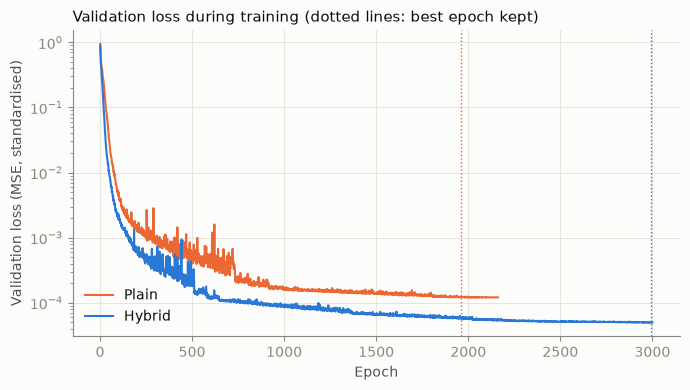

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for kind in ("plain", "hybrid"):
    history = json.loads((ROOT / "models" / f"history_{kind}.json").read_text())
    epochs = np.arange(1, len(history["val_loss"]) + 1)
    ax.semilogy(epochs, history["val_loss"], color=COLOR[kind], linewidth=1.5, label=kind.capitalize())
    ax.axvline(history["best_epoch"], color=COLOR[kind], linewidth=1, linestyle=":")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation loss (MSE, standardised)")
ax.set_title("Validation loss during training (dotted lines: best epoch kept)", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "surrogate_training.png", dpi=150)
plt.show()

## 4. Speed

Step 4 will call the forward model thousands of times while searching for the damage, so speed matters.
We time three things on the same test beams:

- the **FEM** (one eigenvalue solve per beam),
- the surrogate called **one beam at a time** (how a simple search loop would use it),
- the surrogate called on **all beams at once** (a batch).

In [6]:
sample = X_test[:200]
surrogate = models["hybrid"]

start = time.perf_counter()
for row in sample:
    simulate_one(*row)
fem_ms = (time.perf_counter() - start) / len(sample) * 1000

start = time.perf_counter()
for row in sample:
    surrogate.predict(row)
single_ms = (time.perf_counter() - start) / len(sample) * 1000

batch = np.repeat(X_test, 10, axis=0)                       # 6,000 beams
start = time.perf_counter()
surrogate.predict(batch)
batch_ms = (time.perf_counter() - start) / len(batch) * 1000

print(f"{'Method':<30}{'Time per beam (ms)':>20}{'Speed-up vs FEM':>18}")
for name, ms in [("FEM", fem_ms), ("Surrogate, one at a time", single_ms), ("Surrogate, batch of 6,000", batch_ms)]:
    print(f"{name:<30}{ms:>20.4f}{fem_ms / ms:>17.0f}x")

Method                          Time per beam (ms)   Speed-up vs FEM
FEM                                         2.7540                1x
Surrogate, one at a time                    0.2253               12x
Surrogate, batch of 6,000                   0.0010             2701x


## What this shows

- Both surrogates predict frequencies to well under 1 %, but only the **hybrid** predicts the damage drop accurately
  enough to see damage clearly. With the plain network, many beams' damage is comparable to the model's own error.
- The difference comes entirely from physics built into the design: the same network, data and training settings,
  but the hybrid lets the exact formula handle size and material, so the network learns only the effect of damage.
- Every surrogate has a **smallest resolvable damage**, below which the drop is lost in the model error.
  Section 2 measures it rather than assuming it.
- Batched predictions are orders of magnitude faster than the FEM, which is what makes the damage search in
  Step 4 practical.